# Sine waveform generation
_In the context of sound synthesis_

## Content
- sinewave in the continuous domain: 
- sinewave in the discrete domain: calculate the sine output for each sample
- issues when changing the frequency
- using phase instead of sample index
- pseudo code


___
## Continuous sine waveform 

### Simple sin function

In order to generate a sine wavevorm, we need to use the sin function. 

Let's first apply sin to x in the continuous domain as follows:  

`f(x) = sin(x)`

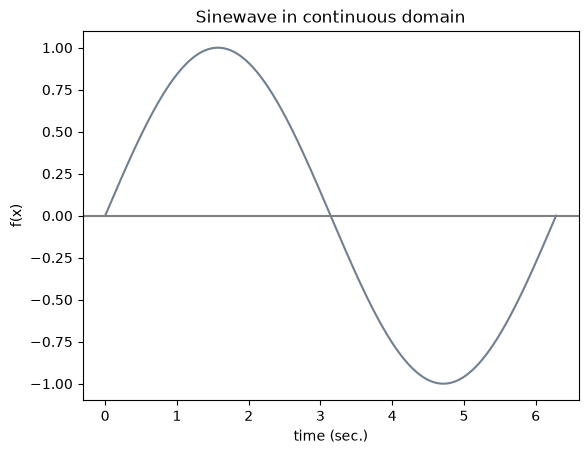

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

"""
numpy.linspace(start, stop, num=50)
    num: int, optional
    Number of samples to generate. Default is 50. Must be non-negative.
see https://numpy.org/doc/stable/reference/generated/numpy.linspace.html
"""

# Generate x values, evenly spaced numbers (number of represented by num) over given interval [0, 2pi] 
x = np.linspace(0, 2 * np.pi, 500)

# Generate plot for x representing [0, 2pi] and the sin function
plt.plot(x, np.sin(x))

plt.xlabel("time (sec.)")
plt.ylabel("f(x)")
plt.title("Sinewave in continuous domain")
# display x axis and show plot
plt.axhline(0, color = "gray")
plt.show()

### Function of time

Now, instead of using x in our function, let's implement our equation as a function in time and use t. 
Additionally, map our sine wave to a period of 1 second. Herefore, we need to multiply t with 2pi.  

`f(t) = sin(2 * pi * t)`


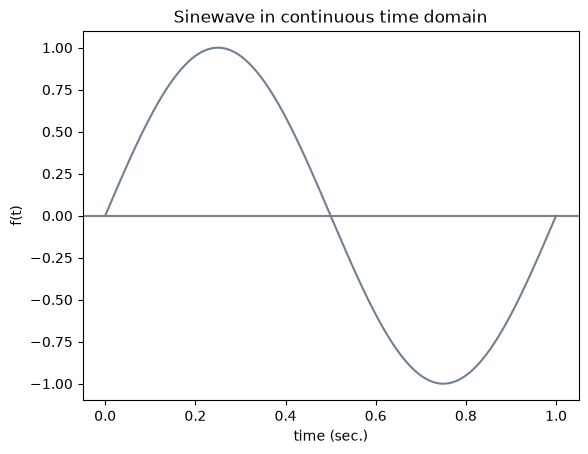

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

# Generate t values, evenly spaced numbers (number of represented by num) over given interval [0, 1] 
t = np.linspace(0, 1, 500)

# Create a plot of a sine wave with frequency 1 in the continuous domain expessed as t. 
# NOTE: we need to multiply t with 2pi to ensure one wave form is finished in 1 second
plt.plot(t, np.sin(2 * np.pi * t))


plt.xlabel("time (sec.)")
plt.ylabel("f(t)")
plt.title("Sinewave in continuous time domain")
plt.axhline(0, color = "gray")
plt.show()

### Frequency

Now, let us also consider the frequency. The previous equation displayed a sinewave with a frequency of 1 Hz; one cycle in one second. 

`f(t) = sin(2 * pi * t)`

A waveform with a frequency of 2 Hz completes its cycle twice per second. In order to let the waveform progress twice as fast, we can simply add a multiplication with two:

`f(t) = sin(2 * 2 * pi * t)`

A waveform with a frequency of 0.5 Hz, only traverses a half cycle per second. For this frequency, we can multiply with 0.5: 

`f(t) = sin(0.5 * 2 * pi * t)`

Concluding; we can extend our the equation of a sine wave generation in continious time domain with the frequency by simply adding a multiplication with the frequency as follows: 

`f(t) = sin(freq * 2 * pi * t)`




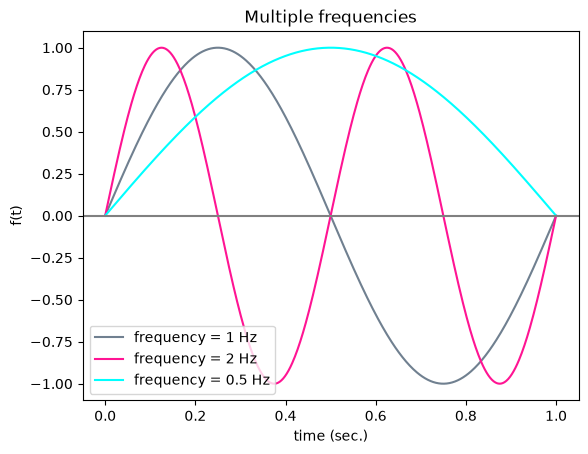

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

# Generate t values, evenly spaced numbers (number of represented by num) over given interval [0, 1] 
t = np.linspace(0, 1, 500)

# AGAIN - generate a plot of a sine in the continuous domain expessed as t
# but now two times, one wave with freq 1Hz and one with freq 3Hz
freq1 = 1
freq2 = 2
freq05 = 0.5
plt.plot(t, np.sin(freq1 * 2 * np.pi * t), label = "frequency = 1 Hz")
plt.plot(t, np.sin(freq2 * 2 * np.pi * t), label = "frequency = 2 Hz")
plt.plot(t, np.sin(freq05 * 2 * np.pi * t), label = "frequency = 0.5 Hz")

plt.xlabel("time (sec.)")
plt.ylabel("f(t)")
plt.legend()
plt.title("Multiple frequencies")
plt.axhline(0, color = "gray")
plt.show()

___
## Discrete domain

Generating a sine wave on a computer takes place in the discrete domain rather than in the continuous domain. Therefore, we transform our equation in the continuous domain to an equation in the discrete domain. 

Previous equation: 

`f(t) = sin(freq * 2 * pi * t)`

New equation:

`f(sample_index) = sin((freq * 2 * pi * sample_index) / samplerate)`

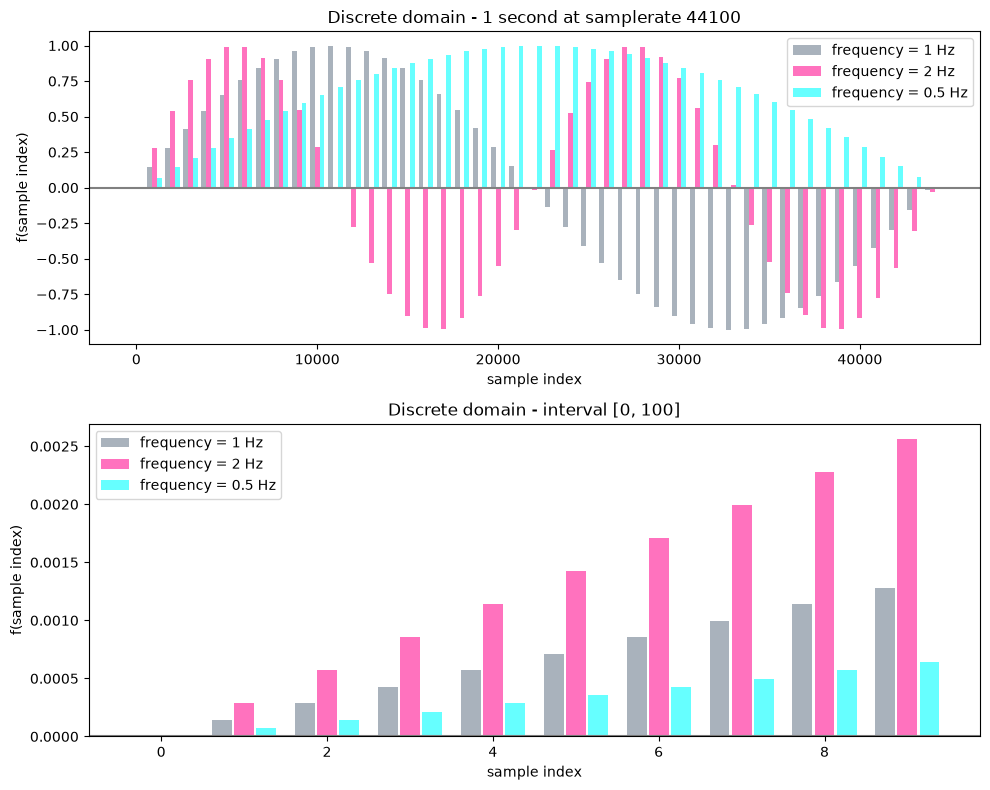

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

freq1 = 1
freq2 = 2
freq05 = 0.5


def get_sine_output(frequency, sample_index, samplerate):
    return np.sin((frequency * 2 * np.pi * sample_index) / samplerate)

# create two plots at once, one for 44100 samples and one zoomed in --> use subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
ax1.set_prop_cycle(color_cycle)
ax2.set_prop_cycle(color_cycle)

# ============ Discrete domain [0, 44100] sample indices =============

# plot bars next to eachother instead of on top of eachother
w =  0.8 / 3.0
step_size = 1000

# Generate sample index values
samplerate = 44100
sample_indices = np.arange(0, samplerate, step_size)

# outputs
y1 = get_sine_output(freq1, sample_indices, samplerate)
y2 = get_sine_output(freq2, sample_indices, samplerate)
y05 = get_sine_output(freq05, sample_indices, samplerate)

# gen bar plots
bar_width = step_size * w
alpha = 0.6
ax1.bar(sample_indices - bar_width, y1, width = bar_width, alpha = alpha, label = "frequency = 1 Hz")
ax1.bar(sample_indices, y2, width = bar_width, alpha = alpha, label = "frequency = 2 Hz")
ax1.bar(sample_indices + bar_width, y05, width = bar_width, alpha = alpha, label = "frequency = 0.5 Hz")

# add line, title, lables and legend
ax1.axhline(0, color = "gray")
ax1.set_title("Discrete domain - 1 second at samplerate " + str(samplerate))
ax1.set_xlabel("sample index")
ax1.set_ylabel("f(sample index)")
ax1.legend()

# ============ Discrete domain [0, 100] sample indices =============

# Generate sample index values
min_sample_index = 0
max_sample_index = 10;
sample_indices = np.arange(min_sample_index, max_sample_index)

# outputs
y1 = get_sine_output(freq1, sample_indices, samplerate)
y2 = get_sine_output(freq2, sample_indices, samplerate)
y05 = get_sine_output(freq05, sample_indices, samplerate)

# gen bar plots

ax2.bar(sample_indices - w, y1, width = w * 0.9, alpha = alpha, label = "frequency = 1 Hz")
ax2.bar(sample_indices, y2, width = w * 0.9, alpha = alpha, label = "frequency = 2 Hz")
ax2.bar(sample_indices + w, y05, width = w * 0.9, alpha = alpha, label = "frequency = 0.5 Hz")
# uncomment below to display full y axis from -1 to 1
#plt.axis([min_sample_index, max_sample_index, -1, 1]) 

# add line, title, lables and legend
ax2.axhline(0, color = "gray")
ax2.set_title("Discrete domain - interval [0, 100]")
ax2.set_xlabel("sample index")
ax2.set_ylabel("f(sample index)")
ax2.legend()

# Adjust spacing so labels do not overlap
plt.tight_layout()
plt.show()

### Periodic waveforms and frequency changes

We can distinquish two issues regarding the latter approach, where we use a function to calculate the output per sample: 
- The sample index 'grows' extremely large, is this really necessary for a periodic function?
- What happens when we change the frequency?

Below, a plot of a sine waveform plotted for the sample index interval [0, 22050), where we switch half way from a frequency of 1 Hz to a frequency of 0.5 Hz. 

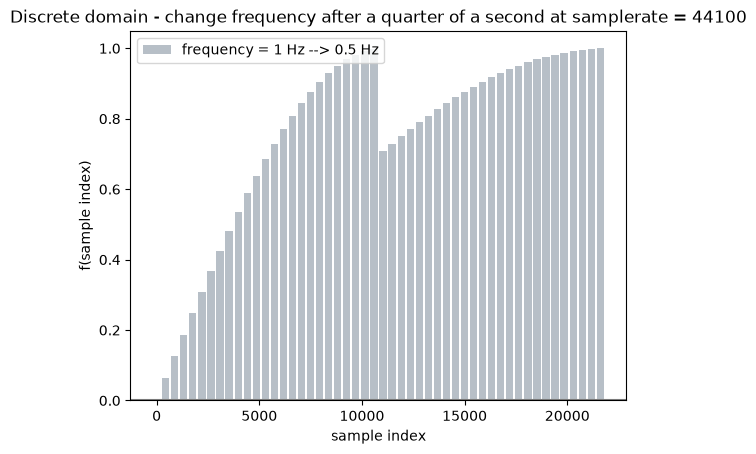

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)


freq1 = 1
freq05 = 0.5

def get_sine_output(frequency, sample_index, samplerate):
    return np.sin(
        (frequency * 2 * np.pi * sample_index) / 
        samplerate
    )

# ============ Discrete domain [0, 44100] sample indices =============

# Generate sample index values
samplerate = 44100
# switch frequency after 1/4 of second
switch_freq_at = samplerate / 4
# range to display
samplerate_range = samplerate / 2
step_size = samplerate_range / 50 
samplerate_half_range = samplerate_range * 0.5
samplerate_index_min = switch_freq_at - samplerate_half_range
samplerate_index_center = samplerate_index_min + samplerate_half_range
samplerate_index_max = switch_freq_at + samplerate_half_range


sample_indices_first_quarter = np.arange(samplerate_index_min, samplerate_index_center, step_size)
sample_indices_second_quarter = np.arange(samplerate_index_center, samplerate_index_max, step_size)
sample_indices_all = np.append(sample_indices_first_quarter, sample_indices_second_quarter)
# outputs
y_first_part = get_sine_output(freq1, sample_indices_first_quarter, samplerate)
y_second_part = get_sine_output(freq05, sample_indices_second_quarter, samplerate)
y_all = np.append(y_first_part, y_second_part)

# gen bar plots
plt.bar(sample_indices_all, y_all, width = step_size * 0.8, alpha = 0.5, label = "frequency = 1 Hz --> 0.5 Hz")

# add line, title, lables and legend
plt.axhline(0, color = "gray")
plt.title("Discrete domain - change frequency after a quarter of a second at samplerate = " + str(samplerate))
plt.xlabel("sample index")
plt.ylabel("f(sample index)")
plt.legend()
plt.show()

___ 
## Periodic waveform as a function of phase

To resolve the aforementioned issues, we can express the equation of a periodic waveform as a function of the phase. Herefore, we can rewrite our equation. 

For the sake of simplicity, let's leave the frequency out of consideration:

`f(sample_index) = sin((2 * pi * sample_index) / samplerate)`


<br>

### _sample_index in [0, samplerate]_

Let's consider the same equation, but reordend:
`f(sample_index) = sin((sample_index / samplerate) * 2 * pi)`

When we consider a sample_index in the range of the interval [0, samplerate], the part `(sample_index / samplerate)` results in the interval [0, 1]

e.g. samplerate = 44100, from `0 / 44100 = 0` to `44100 / 44100 = 1`


<br>

### sample_index in [0, samplerate] --> one cycle

With sample_index in the range of the interval [0, samplerate], the periodic function in our equation completes one cycle. 

`f(sample_index) = sin((sample_index / samplerate) * 2 * pi)` --> [`sin(0.0 * 2 * pi)`, `sin(1.0 * 2 * pi)`]

<br>

### (sample_index / samplerate) --> phase
Since a phase of a periodic waveform traverses repeatedly from 0 to 1, `(sample_index / samplerate)` can be viewed as the phase of the sinewave.
<br>
With `phase = sample_index / samplerate` we can rewrite the equation

`f(sample_index) = sin((sample_index / samplerate) * 2 * pi)`

into:

`f(phase) = sin(phase * 2 * pi)`


<br>

### Increment phase for each subsequent sample
To generate a sinewave with frequency = 1, it is sufficient to keep track of the phase. We can simply increment the phase for each subsequent sample as follows:

`phase += 1 / samplerate`


<br>

### Incorporate the frequency
Now, let's also consider the frequency. Since a frequency determines how quickly a cycle of a periodic function is completed, we can incorporate the frequency in our calculation of the phase incrementation.
`phase += frequency / samplerate`


## Pseudo code

```
# initialize 
samplerate = 44100 
sample = 0
phase = 0 
frequency = 440
phaseIncrement = frequency / samplerate


# increment the phase 
incrementPhase() {
    phase += phaseIncrement
}

calculateSample() {
    sample = sin(phase * 2 * pi)
}


```


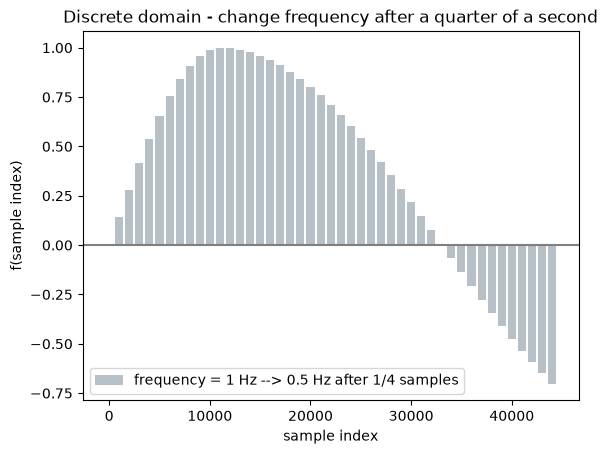

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler

# use custom colors in all examples, which better suit the 0.5 alpha in some examples
color_cycle = cycler(color=["slategray", "deeppink", "aqua"])

# Create the plot and force the color cycle on the current axes
plt.figure()
plt.gca().set_prop_cycle(color_cycle)

samplerate = 44100 
sample = 0
phase = 0 
freq1 = 1
freq05 = 0.5

# increment the phase 
def incrementPhase(phase, frequency, samplerate):
    return phase + frequency / samplerate

def calculateSample(phase):
    return np.sin(phase * 2 * np.pi)   


# ___ Calculate x and y axis values ___
sample_indices = np.arange(0, samplerate)
output = np.zeros(len(sample_indices))

phase = 0.0
frequency = freq1
sampleIndexToChangeFreq = samplerate / 4 
for i in sample_indices:
    output[i] = calculateSample(phase)
    # change frequency 
    if i == sampleIndexToChangeFreq: 
        frequency = freq05
        
    phase = incrementPhase(phase, frequency, samplerate)


# ___ Downsample ___ 
step_size = 1000

# 2. Slice both arrays using [::step_size]
x_axis_indices = sample_indices[::step_size]
y_axis_output = output[::step_size]

# ___ Plot ___


# gen bar plots
plt.bar(x_axis_indices, y_axis_output, width = step_size * 0.8, alpha = 0.5, label = "frequency = 1 Hz --> 0.5 Hz after 1/4 samples")

# add line, title, lables and legend
plt.axhline(0, color = "gray")
plt.title("Discrete domain - change frequency after a quarter of a second")
plt.xlabel("sample index")
plt.ylabel("f(sample index)")
plt.legend()
plt.show()


